Dimensionality Reduction – WineQT

Dataset WineQT memiliki 11 fitur kimia dan kolom target `quality`. Kolom `Id` tidak digunakan sebagai fitur.

Memuat dan Memeriksa Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("data/WineQT.csv")
print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
print(data.info())
print("\nJumlah missing value:")
display(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
None

Jumlah missing value:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Memisahkan Fitur dan Target

`X` berisi 11 fitur kimia. `y` berisi label kualitas wine. Target tidak boleh dimasukkan ke proses PCA karena PCA hanya mereduksi fitur input.

In [3]:
X = data.drop(columns=["Id", "quality"])
y = data["quality"]

print("Jumlah fitur:", X.shape[1])
print("Kelas quality:", sorted(y.unique()))

Jumlah fitur: 11
Kelas quality: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


Melihat Korelasi dan Distribusi Fitur

Korelasi menunjukkan hubungan linear antarfitur. Skewness membantu melihat kemencengan distribusi data.

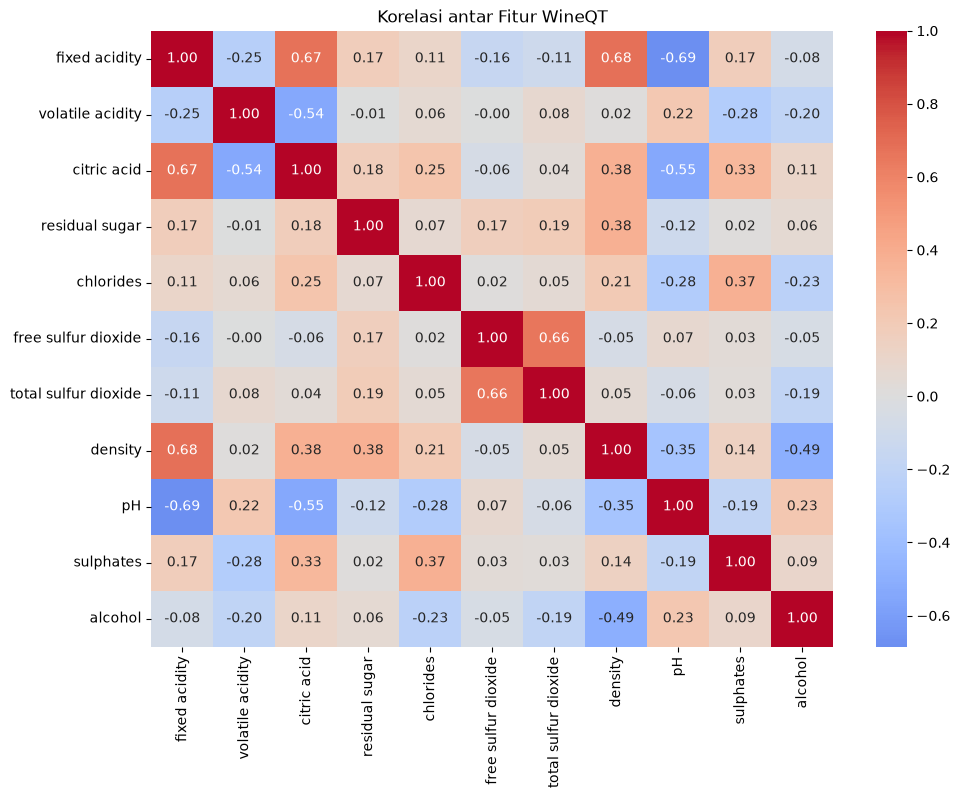

In [4]:
plt.figure(figsize=(11, 8))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar Fitur WineQT")
plt.show()

,skewness
chlorides,6.026360
residual sugar,4.361096
sulphates,2.497266
total sulfur dioxide,1.665766
free sulfur dioxide,1.231261
fixed acidity,1.044930
alcohol,0.863313
volatile acidity,0.681547
citric acid,0.371561
pH,0.221138


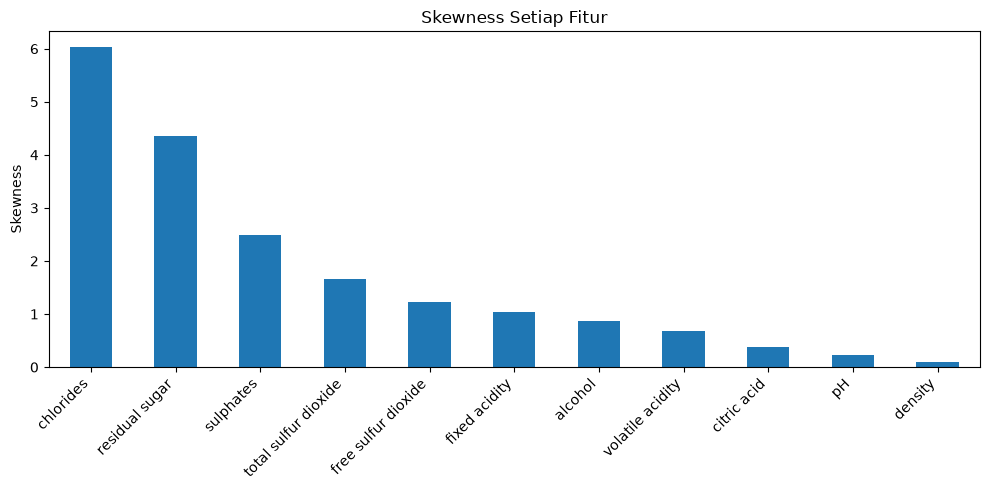

In [5]:
skew_values = X.skew().sort_values(ascending=False)
display(skew_values.to_frame("skewness"))

plt.figure(figsize=(10, 5))
skew_values.plot(kind="bar")
plt.title("Skewness Setiap Fitur")
plt.ylabel("Skewness")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Preprocessing dengan Pipeline

Fitur perlu distandardisasi karena satuan dan rentang nilainya berbeda. Pipeline membantu menyatukan preprocessing dan model agar langkah transformasi dilakukan secara konsisten.

Pada contoh ini digunakan `StandardScaler`.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessing = Pipeline([
    ("scaler", StandardScaler())
])

X_scaled = preprocessing.fit_transform(X)
print("Bentuk data setelah scaling:", X_scaled.shape)

Bentuk data setelah scaling: (1143, 11)


Principal Component Analysis (PCA)

PCA mengubah fitur asli menjadi sejumlah komponen baru yang saling tidak berkorelasi. Komponen disusun berdasarkan banyaknya variasi data yang dapat dijelaskan.

In [7]:
from sklearn.decomposition import PCA

pca_full = PCA()
X_pca = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_summary = pd.DataFrame({
    "Komponen": np.arange(1, len(explained) + 1),
    "Explained Variance": explained,
    "Cumulative Variance": cumulative
})
display(pca_summary)

,Komponen,Explained Variance,Cumulative Variance
0,1,0.286923,0.286923
1,2,0.170751,0.457674
2,3,0.143059,0.600734
3,4,0.110137,0.710871
4,5,0.087110,0.797981
5,6,0.060488,0.858469
6,7,0.050691,0.909160
7,8,0.038096,0.947256
8,9,0.031318,0.978574
9,10,0.016112,0.994686


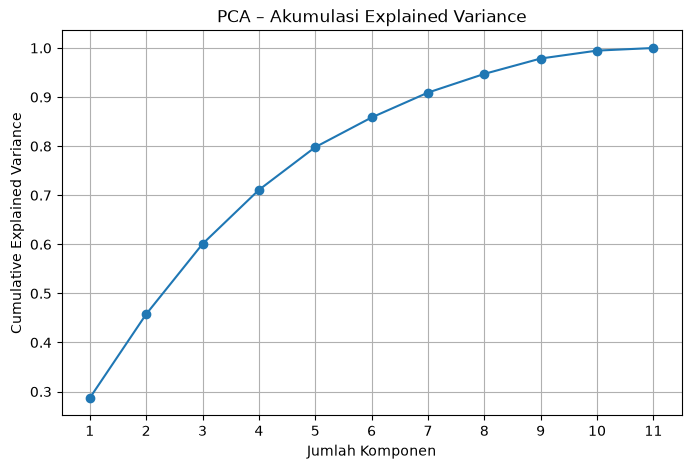

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.xlabel("Jumlah Komponen")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA – Akumulasi Explained Variance")
plt.xticks(range(1, len(cumulative) + 1))
plt.grid(True)
plt.show()

Contohnya, jika 5 komponen sudah menjelaskan sebagian besar variasi data, kita dapat mempertimbangkan memakai 5 komponen daripada seluruh 11 fitur. Keputusan jumlah komponen tetap perlu mempertimbangkan performa model.

Kontribusi Fitur pada Komponen Utama

Nilai *loading* (`components_`) menunjukkan hubungan fitur asli dengan komponen utama. Nilai absolut yang lebih besar menunjukkan kontribusi relatif yang lebih besar pada komponen tersebut.

In [9]:
pca_3 = PCA(n_components=3)
pca_3.fit(X_scaled)

loadings = pd.DataFrame(
    pca_3.components_.T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3"]
)
display(loadings)

,PC1,PC2,PC3
fixed acidity,0.485339,-0.102328,-0.122376
volatile acidity,-0.227143,0.288786,-0.443718
citric acid,0.460075,-0.146508,0.246843
residual sugar,0.174506,0.252262,0.091359
chlorides,0.224870,0.153133,-0.052562
free sulfur dioxide,-0.047852,0.517022,0.428288
total sulfur dioxide,0.015069,0.577393,0.323424
density,0.399684,0.217537,-0.334238
pH,-0.432844,-0.006374,0.059923
sulphates,0.237555,-0.062280,0.302768


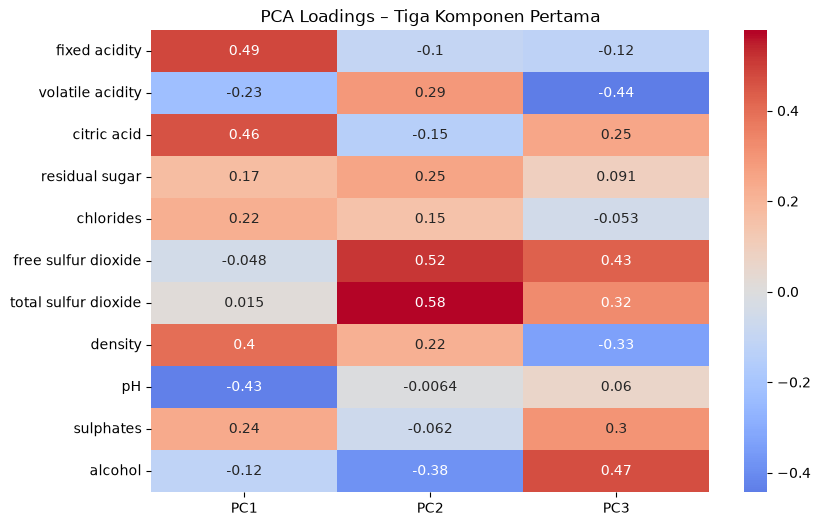

In [10]:
plt.figure(figsize=(9, 6))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0)
plt.title("PCA Loadings – Tiga Komponen Pertama")
plt.show()

Visualisasi Data dengan Dua Komponen PCA

Visualisasi ini memproyeksikan data ke dua komponen utama. Warna menunjukkan nilai `quality` untuk membantu melihat pola, bukan sebagai bagian dari proses PCA.

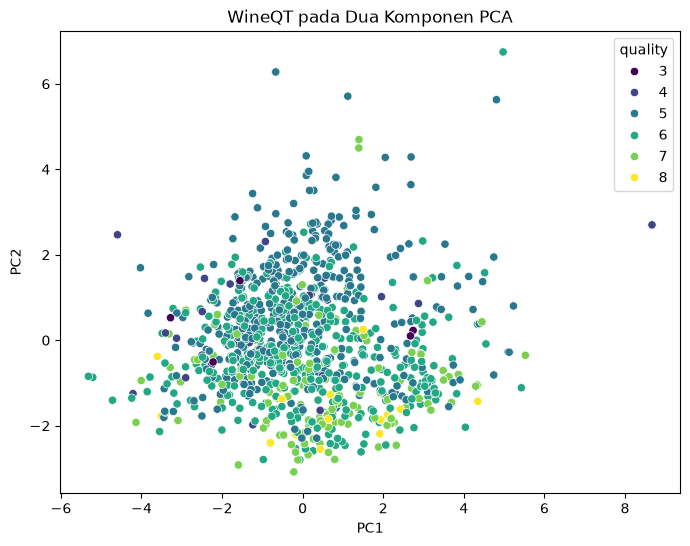

In [11]:
pca_2 = PCA(n_components=2)
X_2d = pca_2.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "quality": y.to_numpy()
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="quality", palette="viridis")
plt.title("WineQT pada Dua Komponen PCA")
plt.show()

Kernel PCA

Kernel PCA dapat menangkap pola non-linear dengan menggunakan kernel, misalnya `rbf`. Berbeda dari PCA biasa yang berfokus pada kombinasi linear fitur, Kernel PCA memetakan data melalui fungsi kernel.

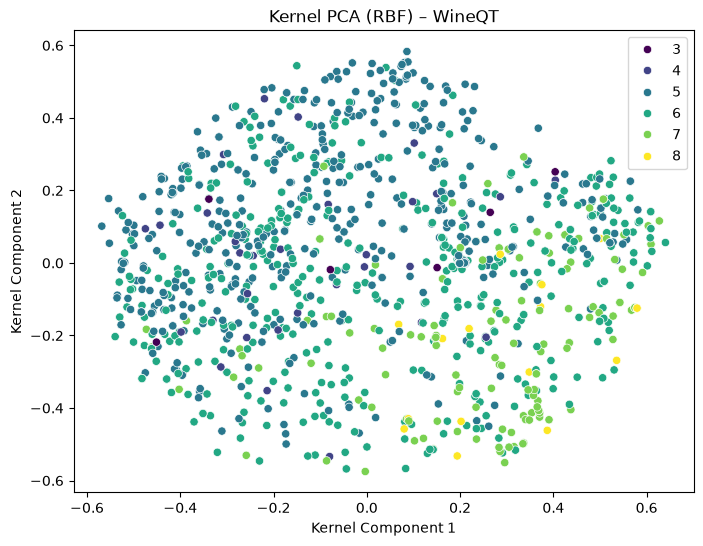

In [12]:
from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=2, kernel="rbf", gamma=0.1)
X_kpca = kpca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_kpca[:, 0], y=X_kpca[:, 1],
    hue=y.to_numpy(), palette="viridis"
)
plt.xlabel("Kernel Component 1")
plt.ylabel("Kernel Component 2")
plt.title("Kernel PCA (RBF) – WineQT")
plt.show()

Pengaruh Jumlah Komponen terhadap Akurasi Model

Bagian ini mengikuti ide eksperimen pada notebook sumber: membandingkan akurasi Logistic Regression ketika jumlah dimensi/komponen PCA diubah.

Pipeline berisi:
1. `StandardScaler`
2. `PCA(n_components=n)`
3. `LogisticRegression`

Evaluasi memakai Stratified 5-Fold Cross Validation agar proporsi kelas tetap relatif terjaga pada setiap fold.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_components_list = list(range(1, X.shape[1] + 1))
mean_scores = []

for n in n_components_list:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    mean_scores.append(scores.mean())

accuracy_results = pd.DataFrame({
    "Jumlah Komponen": n_components_list,
    "Rata-rata Akurasi": mean_scores
})
display(accuracy_results)

,Jumlah Komponen,Rata-rata Akurasi
0,1,0.415575
1,2,0.513621
2,3,0.589692
3,4,0.583559
4,5,0.591423
5,6,0.586187
6,7,0.584444
7,8,0.583594
8,9,0.606313
9,10,0.601050


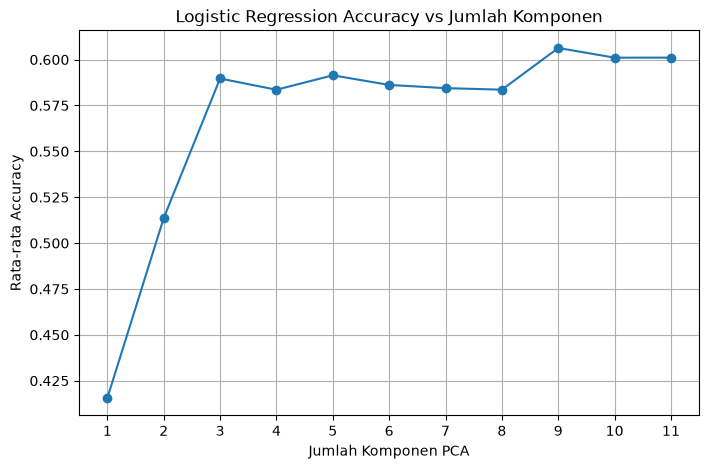

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(n_components_list, mean_scores, marker="o")
plt.xlabel("Jumlah Komponen PCA")
plt.ylabel("Rata-rata Accuracy")
plt.title("Logistic Regression Accuracy vs Jumlah Komponen")
plt.xticks(n_components_list)
plt.grid(True)
plt.show()

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.